In [1]:
import pandas as pd

df = pd.read_csv("../data/archive/boneage-training-dataset.csv")
print(df.head())
print(df.shape)


     id  boneage   male
0  1377      180  False
1  1378       12  False
2  1379       94  False
3  1380      120   True
4  1381       82  False
(12611, 3)


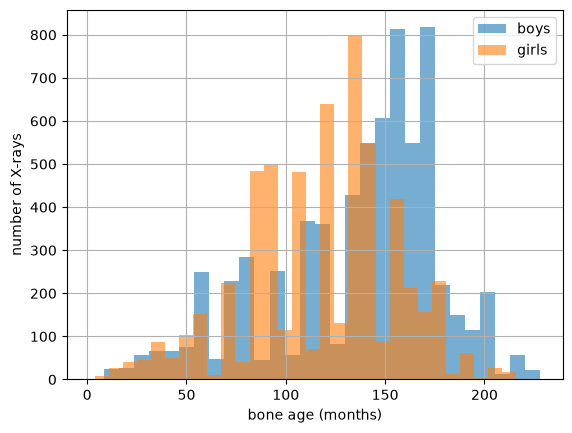

In [2]:
import matplotlib.pyplot as plt

df[df.male == True].boneage.hist(alpha=0.6, bins=30, label="boys")
df[df.male == False].boneage.hist(alpha=0.6, bins=30, label="girls")
plt.xlabel("bone age (months)")
plt.ylabel("number of X-rays")
plt.legend()
plt.show()

picture size (height, width): (2044, 1514)
bone age: 180 months | boy? False


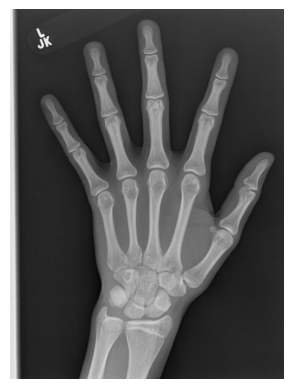

In [3]:
import cv2
import matplotlib.pyplot as plt

row = df.iloc[0]
path = f"../data/archive/boneage-training-dataset/boneage-training-dataset/{row.id}.png"

img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
print("picture size (height, width):", img.shape)
print("bone age:", row.boneage, "months | boy?", row.male)

plt.imshow(img, cmap="gray")
plt.axis("off")
plt.show()

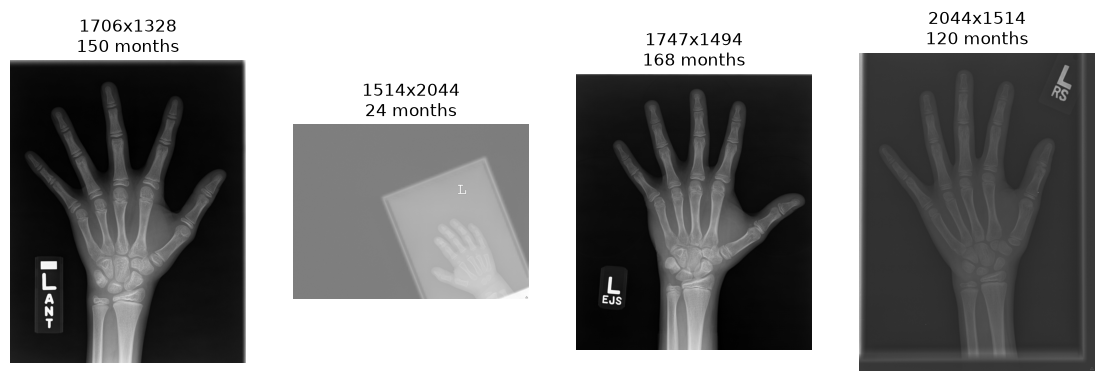

In [4]:
IMG_DIR = "../data/archive/boneage-training-dataset/boneage-training-dataset"

fig, axes = plt.subplots(1, 4, figsize=(14, 5))
for ax, (_, r) in zip(axes, df.sample(4, random_state=1).iterrows()):
    im = cv2.imread(f"{IMG_DIR}/{r.id}.png", cv2.IMREAD_GRAYSCALE)
    ax.imshow(im, cmap="gray")
    ax.set_title(f"{im.shape[0]}x{im.shape[1]}\n{r.boneage} months")
    ax.axis("off")
plt.show()

In [5]:
import numpy as np

def load_hand(path, size=512):
    img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    h, w = img.shape
    s = max(h, w)                          # the longer side decides the square size
    pad = np.zeros((s, s), np.uint8)       # an all-black square
    top, left = (s - h) // 2, (s - w) // 2
    pad[top:top + h, left:left + w] = img  # put the X-ray in the middle
    return cv2.resize(pad, (size, size), interpolation=cv2.INTER_AREA)

new size: (512, 512)


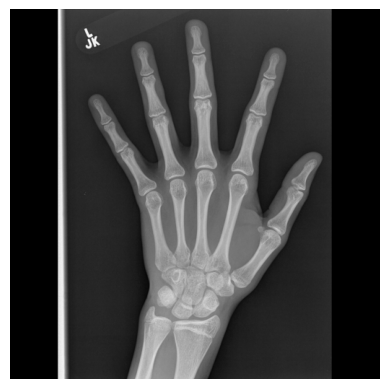

In [6]:
test = load_hand(f"{IMG_DIR}/{df.iloc[0].id}.png")
print("new size:", test.shape)
plt.imshow(test, cmap="gray")
plt.axis("off")
plt.show()

In [7]:
MEAN, STD = df.boneage.mean(), df.boneage.std()
df["target"] = (df.boneage - MEAN) / STD
df["male"] = df["male"].astype(float)

print("average bone age:", round(MEAN, 1), "months")
print("spread (STD):", round(STD, 1), "months")

# the lazy baseline: always guess the average
baseline = (df.boneage - MEAN).abs().mean()
print("baseline error if we always guess the average:", round(baseline, 1), "months")

average bone age: 127.3 months
spread (STD): 41.2 months
baseline error if we always guess the average: 33.6 months


In [8]:
from sklearn.model_selection import train_test_split

# 80% study pile, 20% exam pile (random, fixed seed so it's the same every time)
train_df, val_df = train_test_split(df, test_size=0.2, random_state=42)
train_df = train_df.copy()
val_df = val_df.copy()

# Recompute the average and spread using ONLY the study pile (the exam must not peek)
MEAN = train_df["boneage"].mean()
STD = train_df["boneage"].std()
train_df["target"] = (train_df["boneage"] - MEAN) / STD
val_df["target"] = (val_df["boneage"] - MEAN) / STD

print("Study pile:", len(train_df), "  Exam pile:", len(val_df))
print("MEAN:", round(MEAN, 2), "  STD:", round(STD, 2))

# Baseline: always guess the study-pile average, then see how wrong that is on the exam pile
baseline_mae = (val_df["boneage"] - MEAN).abs().mean()
print("Baseline MAE (months):", round(baseline_mae, 1))

Study pile: 10088   Exam pile: 2523
MEAN: 127.2   STD: 40.95
Baseline MAE (months): 34.5


In [9]:
import os, json

os.makedirs("../splits", exist_ok=True)

train_df.to_csv("../splits/train.csv", index=False)
val_df.to_csv("../splits/val.csv", index=False)

with open("../splits/stats.json", "w") as f:
    json.dump({"MEAN": float(MEAN), "STD": float(STD), "baseline_mae": float(baseline_mae)}, f)

print(os.listdir("../splits"))

['stats.json', 'train.csv', 'val.csv']


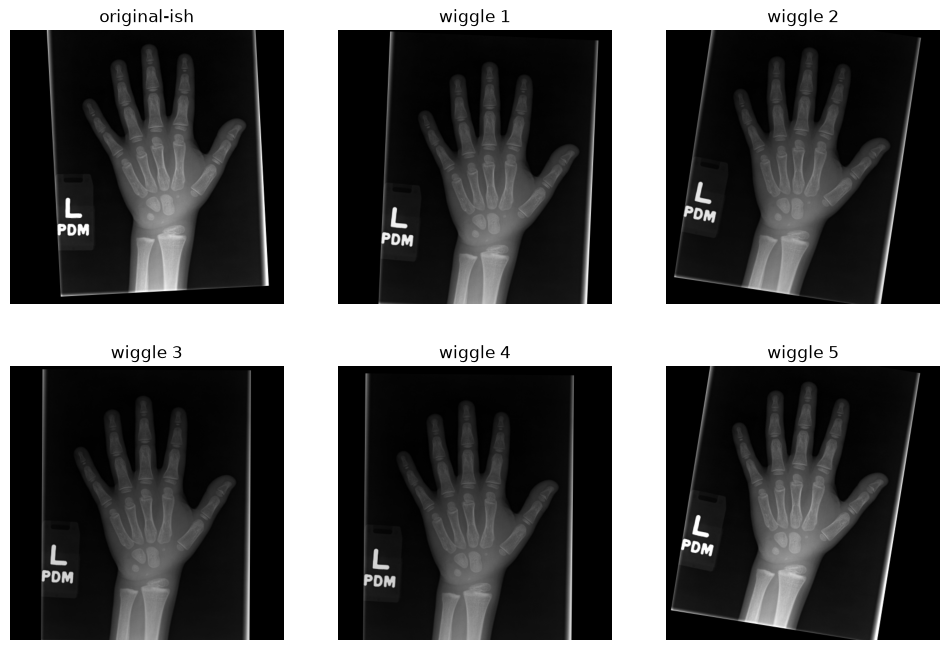

In [1]:
import sys
sys.path.append("..")   # lets the notebook find the src folder

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.dataset import BoneAgeDataset, IMAGENET_MEAN, IMAGENET_STD

IMG_DIR = r"..\data\archive\boneage-training-dataset\boneage-training-dataset"
train_check = pd.read_csv("../splits/train.csv")

ds = BoneAgeDataset(train_check, IMG_DIR, train=True)

fig, axes = plt.subplots(2, 3, figsize=(12, 8))
for k, ax in enumerate(axes.flat):
    img, male, y = ds[0]                      # same child every time
    pic = (img.numpy() * IMAGENET_STD + IMAGENET_MEAN)[0]   # undo the color matching
    ax.imshow(pic, cmap="gray", vmin=0, vmax=1)
    ax.set_title("original-ish" if k == 0 else f"wiggle {k}")
    ax.axis("off")
plt.show()

In [1]:
{
  "mae": 6.939232349395752,
  "mae_boys": 6.740237236022949,
  "mae_girls": 7.183756351470947,
  "epoch": 9,
  "baseline_mae": 34.513076366736094
}

{'mae': 6.939232349395752,
 'mae_boys': 6.740237236022949,
 'mae_girls': 7.183756351470947,
 'epoch': 9,
 'baseline_mae': 34.513076366736094}